<a href="https://colab.research.google.com/github/PatrickP6226/ics294-latex/blob/main/trabajo/informe_final/proyecto_ceosal1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Proyecto Econometría — Código del informe final
## Salarios de CEOs y desempeño de las empresas (`ceosal1`)

**Universidad Técnica Federico Santa María** · Ingeniería Comercial<br>
**Asignatura:** Econometría ICS-294 · Semestre 2026-2<br>
**Profesor:** Francisco Alfaro Medina<br>
**Entrega:** Trabajo Práctico, informe + código · 30 de noviembre de 2026

**Integrantes:** Jorge Figueroa, Patrick Peñaloza, Joaquín Rubio, Felipe Hormachea, Felipe Vidal, Fernanda Nuñez.

**Base de datos:** `ceosal1`, paquete `wooldridge` de R<br>
**Pregunta de investigación:** ¿se asocia el salario de los CEOs con el desempeño de sus empresas, una vez que se considera el tamaño de la firma y el sector en que opera?

### Contenido del cuaderno

Este cuaderno contiene todo el código en R que permite replicar los resultados del informe, con una breve explicación de cada paso:

| Sección | Contenido |
|---|---|
| 1 | Descripción de la base de datos, su origen y sus variables |
| 2 | Medidas de tendencia central y dispersión, composición por sector y correlaciones |
| 3 | Gráficos descriptivos |
| 4 | Pregunta de investigación, justificación de variables, modelo poblacional e hipótesis |
| 5 | Estimación del modelo por MCO e interpretación de los coeficientes |
| 6 | Verificación de supuestos: exogeneidad, homocedasticidad, normalidad y multicolinealidad |
| 7 | Correcciones: errores estándar robustos |
| 8 | Testeo de las hipótesis de investigación con el modelo corregido |
| 9 | Análisis de robustez: valores atípicos y forma funcional |
| 10 | Conclusiones, limitaciones y recomendaciones |

> **Para ejecutar en Google Colab:** el cuaderno usa R. Si Colab lo abre con Python, ir a *Entorno de ejecución → Cambiar tipo de entorno de ejecución → R* y luego *Ejecutar todas*. La primera celda instala los paquetes que falten (puede tardar unos minutos).

In [1]:
# ============================================================
# 0. Dependencias
# ============================================================

# Paquetes que usa el cuaderno:
#  - wooldridge: contiene la base ceosal1
#  - dplyr / tidyr: manipulación de datos
#  - ggplot2: gráficos
#  - corrplot: gráfico de la matriz de correlaciones
#  - lmtest: pruebas de Breusch-Pagan, RESET y coeftest()
#  - sandwich: errores estándar robustos (vcovHC)
#  - car: VIF y pruebas F de restricciones lineales
#  - tseries: prueba de normalidad de Jarque-Bera
paquetes <- c("wooldridge", "dplyr", "tidyr", "ggplot2", "corrplot",
              "lmtest", "sandwich", "car", "tseries")

# Se instalan solo los paquetes que no estén disponibles
instalar <- paquetes[!(paquetes %in% installed.packages()[, "Package"])]
if (length(instalar)) install.packages(instalar)

# Se cargan todos los paquetes
invisible(lapply(paquetes, library, character.only = TRUE))

# Tamaño por defecto de los gráficos en el cuaderno
options(repr.plot.width = 9, repr.plot.height = 5)


Attaching package: ‘dplyr’




The following objects are masked from ‘package:stats’:

    filter, lag




The following objects are masked from ‘package:base’:

    intersect, setdiff, setequal, union




corrplot 0.92 loaded



Loading required package: zoo




Attaching package: ‘zoo’




The following objects are masked from ‘package:base’:

    as.Date, as.Date.numeric




Loading required package: carData




Attaching package: ‘car’




The following object is masked from ‘package:dplyr’:

    recode




Registered S3 method overwritten by 'quantmod':
  method            from
  as.zoo.data.frame zoo 



## 1. Descripción de la base de datos

### 1.1 Origen y tipo de datos

La base `ceosal1` proviene del paquete `wooldridge` de R, que reúne los conjuntos de datos del libro *Introductory Econometrics: A Modern Approach* de Jeffrey M. Wooldridge. Según la documentación del paquete, Wooldridge construyó la base a partir de una **muestra aleatoria de los datos publicados en la edición del 6 de mayo de 1991 de la revista *Businessweek***, que informaba la remuneración de los máximos ejecutivos (CEOs) de grandes empresas de Estados Unidos.

- **Tipo de datos:** corte transversal (cada empresa se observa una sola vez).
- **Unidad de observación:** el CEO de una empresa estadounidense y su firma.
- **Período:** el salario y las ventas corresponden a 1990; las medidas de rentabilidad son promedios o variaciones del período 1988–1990.
- **Tamaño:** 209 observaciones y 12 variables.

En el libro la base se usa para estudiar cómo el salario del CEO responde al tamaño de la empresa (ventas) y a su rentabilidad (ROE), lo que coincide con el tema de este trabajo.

### 1.2 Diccionario de variables

| Variable | Descripción | Unidad | Tipo |
|---|---|---|---|
| `salary` | Salario del CEO en 1990 | miles de USD | Continua |
| `pcsalary` | Variación porcentual del salario entre 1989 y 1990 | % | Continua |
| `sales` | Ventas de la empresa en 1990 | millones de USD | Continua |
| `roe` | Rentabilidad sobre el patrimonio (*return on equity*), promedio 1988–1990 | % | Continua |
| `pcroe` | Variación porcentual del ROE entre 1988 y 1990 | % | Continua |
| `ros` | Rentabilidad de la acción de la empresa (*return on stock*), 1988–1990 | % | Continua |
| `indus` | 1 si la empresa es industrial | 0/1 | Dummy |
| `finance` | 1 si la empresa es financiera | 0/1 | Dummy |
| `consprod` | 1 si la empresa produce bienes de consumo | 0/1 | Dummy |
| `utility` | 1 si la empresa es de servicios públicos o transporte | 0/1 | Dummy |
| `lsalary` | Logaritmo natural de `salary` | log | Continua |
| `lsales` | Logaritmo natural de `sales` | log | Continua |

Las cuatro dummies de sector son mutuamente excluyentes: cada empresa pertenece a exactamente uno de los cuatro sectores (se verifica en la sección 1.3).

In [2]:
# ============================================================
# 1. Carga de datos
# ============================================================

data("ceosal1")          # carga la base desde el paquete wooldridge
ceo <- ceosal1           # copia de trabajo

dim(ceo)                 # número de observaciones y de variables
str(ceo)                 # tipo de cada variable
head(ceo)                # primeras filas

[1] 209  12

'data.frame':	209 obs. of  12 variables:
 $ salary  : int  1095 1001 1122 578 1368 1145 1078 1094 1237 833 ...
 $ pcsalary: int  20 32 9 -9 7 5 10 7 16 5 ...
 $ sales   : num  27595 9958 6126 16246 21783 ...
 $ roe     : num  14.1 10.9 23.5 5.9 13.8 ...
 $ pcroe   : num  106.4 -30.6 -16.3 -25.7 -3 ...
 $ ros     : int  191 13 14 -21 56 55 62 44 37 37 ...
 $ indus   : int  1 1 1 1 1 1 1 1 1 1 ...
 $ finance : int  0 0 0 0 0 0 0 0 0 0 ...
 $ consprod: int  0 0 0 0 0 0 0 0 0 0 ...
 $ utility : int  0 0 0 0 0 0 0 0 0 0 ...
 $ lsalary : num  7 6.91 7.02 6.36 7.22 ...
 $ lsales  : num  10.23 9.21 8.72 9.7 9.99 ...
 - attr(*, "time.stamp")= chr "25 Jun 2011 23:03"


,salary,pcsalary,sales,roe,pcroe,ros,indus,finance,consprod,utility,lsalary,lsales
,<int>,<int>,<dbl>,<dbl>,<dbl>,<int>,<int>,<int>,<int>,<int>,<dbl>,<dbl>
1,1095,20,27595.0,14.1,106.4,191,1,0,0,0,6.998509,10.225389
2,1001,32,9958.0,10.9,-30.6,13,1,0,0,0,6.908755,9.206132
3,1122,9,6125.9,23.5,-16.3,14,1,0,0,0,7.022868,8.720281
4,578,-9,16246.0,5.9,-25.7,-21,1,0,0,0,6.359574,9.695602
5,1368,7,21783.2,13.8,-3.0,56,1,0,0,0,7.221105,9.988894
6,1145,5,6021.4,20.0,1.0,55,1,0,0,0,7.043160,8.703075


### 1.3 Revisión de datos nulos y consistencia

Antes del análisis se revisa si existen valores perdidos, si las dummies de sector clasifican a cada empresa en un único sector y si las variables en logaritmo coinciden con las variables originales.

In [3]:
# Valores perdidos por columna y en total
colSums(is.na(ceo))
sum(is.na(ceo))

# Cada empresa debe pertenecer a un solo sector
# (la suma de las cuatro dummies debe ser 1)
table(ceo$indus + ceo$finance + ceo$consprod + ceo$utility)

# lsalary y lsales deben ser el logaritmo de salary y sales
all.equal(ceo$lsalary, log(ceo$salary), tolerance = 1e-4)
all.equal(ceo$lsales,  log(ceo$sales),  tolerance = 1e-4)

# Variable categórica de sector, útil para tablas y gráficos
ceo$sector <- factor(
  case_when(ceo$indus == 1    ~ "Industrial",
            ceo$finance == 1  ~ "Financiero",
            ceo$consprod == 1 ~ "Consumo",
            ceo$utility == 1  ~ "Utilities/transporte"),
  levels = c("Industrial", "Financiero", "Consumo",
             "Utilities/transporte"))
table(ceo$sector)

salary pcsalary    sales      roe    pcroe      ros    indus  finance 
       0        0        0        0        0        0        0        0 
consprod  utility  lsalary   lsales 
       0        0        0        0

[1] 0


  1 
209 

[1] TRUE

[1] TRUE


          Industrial           Financiero              Consumo 
                  67                   46                   60 
Utilities/transporte 
                  36 

La base no presenta valores perdidos, por lo que se trabaja con las 209 observaciones. Cada empresa pertenece a un solo sector y las variables `lsalary` y `lsales` corresponden efectivamente al logaritmo de `salary` y `sales`. La muestra se reparte entre empresas industriales (67), de bienes de consumo (60), financieras (46) y de servicios públicos o transporte (36).

## 2. Estadística descriptiva

### 2.1 Medidas de tendencia central y dispersión

Para cada variable continua se calculan:

- **Tendencia central:** media y mediana.
- **Dispersión:** desviación estándar (DE), coeficiente de variación (CV = DE/media), rango (mínimo y máximo) y rango intercuartílico (RIC = Q3 − Q1).
- **Forma:** asimetría (0 en una distribución simétrica; positiva si hay cola larga a la derecha) y curtosis (3 en una distribución normal; mayor a 3 indica colas pesadas o valores extremos).

In [4]:
# ============================================================
# 2. Estadística descriptiva
# ============================================================

# Asimetría y curtosis calculadas con momentos muestrales
asimetria <- function(x) {
  m <- mean(x)
  mean((x - m)^3) / mean((x - m)^2)^(3/2)
}
curtosis <- function(x) {
  m <- mean(x)
  mean((x - m)^4) / mean((x - m)^2)^2
}

# Función que resume una variable numérica
resumen <- function(x) {
  c(Media     = mean(x),
    Mediana   = median(x),
    DE        = sd(x),
    CV        = sd(x) / mean(x),
    Min       = min(x),
    Q1        = unname(quantile(x, 0.25)),
    Q3        = unname(quantile(x, 0.75)),
    Max       = max(x),
    RIC       = IQR(x),
    Asimetria = asimetria(x),
    Curtosis  = curtosis(x))
}

vars_continuas <- c("salary", "lsalary", "sales", "lsales",
                    "roe", "ros", "pcsalary", "pcroe")

tabla_desc <- t(sapply(ceo[, vars_continuas], resumen))

# Tendencia central y dispersión
round(tabla_desc[, c("Media", "Mediana", "DE", "CV", "Min", "Max")], 3)

# Posición y forma de la distribución
round(tabla_desc[, c("Q1", "Q3", "RIC", "Asimetria", "Curtosis")], 3)

,Media,Mediana,DE,CV,Min,Max
salary,1281.120,1039.000,1372.345,1.071,223.000,14822.000
lsalary,6.950,6.946,0.566,0.081,5.407,9.604
sales,6923.793,3705.200,10633.271,1.536,175.200,97649.898
lsales,8.292,8.217,1.013,0.122,5.166,11.489
roe,17.184,15.500,8.519,0.496,0.500,56.300
ros,61.804,52.000,68.177,1.103,-58.000,418.000
pcsalary,13.282,9.000,32.634,2.457,-61.000,212.000
pcroe,10.800,-3.000,97.219,9.001,-98.900,977.000


,Q1,Q3,RIC,Asimetria,Curtosis
salary,736.000,1407.000,671.000,6.855,60.541
lsalary,6.601,7.249,0.648,0.880,6.268
sales,2210.300,7177.000,4966.700,4.999,35.300
lsales,7.701,8.879,1.178,0.094,3.755
roe,12.400,20.000,7.600,1.561,6.679
ros,21.000,81.000,60.000,2.080,9.400
pcsalary,-1.000,20.000,21.000,2.734,15.282
pcroe,-21.200,19.500,40.700,6.417,56.099


**Interpretación de las variables clave**

- **Salario (`salary`).** El salario medio es de 1 281 miles de dólares (USD 1,28 millones), pero la mediana es menor, 1 039 miles: la mitad de los CEOs gana menos de USD 1,04 millones. La desviación estándar (1 372) supera a la media (CV = 1,07), y el rango va de 223 a 14 822 miles de dólares. La asimetría (6,9) y la curtosis (≈61) son muy altas: unos pocos CEOs con remuneraciones excepcionales alejan la media de la mediana.
- **Logaritmo del salario (`lsalary`).** Al aplicar logaritmo la media (6,95) y la mediana (6,95) prácticamente coinciden, el CV baja a 0,08 y la asimetría se reduce a 0,88. La transformación logarítmica vuelve la distribución mucho más simétrica, lo que respalda usar `lsalary` como variable dependiente (sección 4.2).
- **Ventas (`sales`).** Las empresas son grandes y muy heterogéneas: las ventas medias son USD 6 924 millones, la mediana USD 3 705 millones, y el rango va de USD 175 millones a casi USD 97 650 millones (CV = 1,54; asimetría 5,0). En logaritmo (`lsales`) la asimetría es prácticamente nula (0,09).
- **Rentabilidad sobre el patrimonio (`roe`).** El ROE promedio de 1988–1990 es 17,2 % y la mediana 15,5 %. La DE es 8,5 puntos porcentuales (CV = 0,50) y el rango va de 0,5 % a 56,3 %. Todas las empresas tuvieron ROE positivo, con una cola moderada hacia la derecha (asimetría 1,56).
- **Rentabilidad de la acción (`ros`).** La rentabilidad bursátil acumulada promedio es 61,8 % (mediana 52 %), con una dispersión muy alta: va de −58 % a 418 % (DE = 68,2). 23 empresas tuvieron rentabilidad bursátil negativa en el período.
- **Variaciones porcentuales (`pcsalary`, `pcroe`).** Ambas son muy dispersas; en particular `pcroe` tiene un CV de 9 y un máximo de 977 %, producto de empresas que partían de un ROE cercano a cero. Por esta razón no se usan como variables explicativas (sección 4.3).

### 2.2 Variables binarias: composición por sector

En las variables dummy la media corresponde a la proporción de empresas que pertenecen a cada sector. Además, se comparan las variables clave entre sectores.

In [5]:
# Proporción de empresas en cada sector
dummies <- c("indus", "finance", "consprod", "utility")
round(sapply(ceo[, dummies], mean), 3)

# Salario del CEO por sector
ceo %>%
  group_by(sector) %>%
  summarise(n               = n(),
            salario_medio   = mean(salary),
            salario_mediana = median(salary),
            lsalary_medio   = mean(lsalary)) %>%
  mutate(across(where(is.numeric), ~ round(.x, 2)))

# Tamaño y rentabilidad promedio de las empresas por sector
ceo %>%
  group_by(sector) %>%
  summarise(ventas_medias = mean(sales),
            roe_medio     = mean(roe),
            ros_medio     = mean(ros)) %>%
  mutate(across(where(is.numeric), ~ round(.x, 2)))

indus  finance consprod  utility 
   0.321    0.220    0.287    0.172

sector,n,salario_medio,salario_mediana,lsalary_medio
<fct>,<dbl>,<dbl>,<dbl>,<dbl>
Industrial,67,1139.34,1041.0,6.94
Financiero,46,1344.91,1119.5,7.06
Consumo,60,1722.42,1246.0,7.15
Utilities/transporte,36,727.97,646.0,6.51


sector,ventas_medias,roe_medio,ros_medio
<fct>,<dbl>,<dbl>,<dbl>
Industrial,8369.39,17.35,41.06
Financiero,5844.05,14.33,47.98
Consumo,8080.15,22.66,99.08
Utilities/transporte,3685.80,11.41,55.94


El 32,1 % de las empresas es industrial, el 28,7 % produce bienes de consumo, el 22,0 % es financiera y el 17,2 % pertenece a servicios públicos o transporte.

Las diferencias entre sectores son marcadas. Los CEOs de empresas de **bienes de consumo** tienen el salario medio más alto (1 722 miles de dólares) y esas empresas también muestran la mayor rentabilidad (ROE medio 22,7 %, rentabilidad bursátil media 99 %). En el otro extremo, los CEOs de **servicios públicos y transporte** ganan en promedio 728 miles de dólares, poco más de la mitad que el resto, y sus empresas son las de menor ventas y menor ROE. Esto sugiere que el sector debe incluirse en el modelo: si se omitiera, parte de las diferencias de salario entre sectores se atribuiría erróneamente al desempeño o al tamaño.

### 2.3 Correlaciones

La matriz de correlaciones muestra la asociación lineal simple entre pares de variables. Se usan las variables en la forma en que entrarán al modelo (salario y ventas en logaritmo).

,lsalary,lsales,roe,ros,finance,consprod,utility
lsalary,1.000,0.459,0.208,-0.075,0.101,0.220,-0.355
lsales,0.459,1.000,-0.123,-0.350,0.039,-0.019,-0.094
roe,0.208,-0.123,1.000,0.275,-0.179,0.409,-0.310
ros,-0.075,-0.350,0.275,1.000,-0.108,0.348,-0.039
finance,0.101,0.039,-0.179,-0.108,1.000,-0.337,-0.242
consprod,0.220,-0.019,0.409,0.348,-0.337,1.000,-0.289
utility,-0.355,-0.094,-0.310,-0.039,-0.242,-0.289,1.000


lsales      roe      ros 
2.70e-12 2.45e-03 2.83e-01

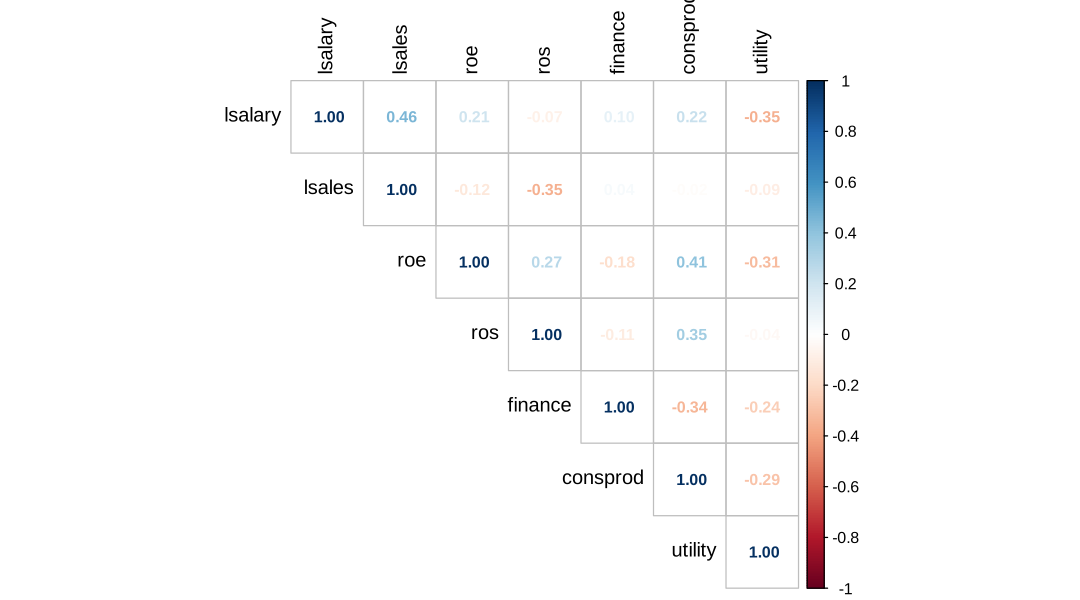

In [6]:
# Matriz de correlaciones de las variables del modelo
vars_modelo <- ceo[, c("lsalary", "lsales", "roe", "ros",
                       "finance", "consprod", "utility")]
round(cor(vars_modelo), 3)

# Pruebas de significancia de la correlación con lsalary
p_valores <- sapply(c("lsales", "roe", "ros"),
                    function(v) cor.test(ceo$lsalary, ceo[[v]])$p.value)
signif(p_valores, 3)

# Visualización
corrplot(cor(vars_modelo), method = "number", type = "upper",
         tl.col = "black", number.cex = 0.8)

**Interpretación de las correlaciones**

- **`lsalary` y `lsales` (0,46):** es la correlación más fuerte con el salario y es estadísticamente significativa (p < 0,001). Las empresas más grandes pagan más a sus CEOs.
- **`lsalary` y `roe` (0,21):** correlación positiva, débil pero significativa al 1 % (p ≈ 0,002). Las empresas más rentables tienden a pagar salarios más altos.
- **`lsalary` y `ros` (−0,08):** prácticamente nula y no significativa (p ≈ 0,28). A primera vista, el desempeño bursátil no se asocia con el salario.
- **`lsalary` y `utility` (−0,36):** confirma que los CEOs de servicios públicos ganan menos; `consprod` se asocia positivamente (0,22).
- **Entre explicativas:** `roe` y `ros` se correlacionan positivamente (0,28), igual que `roe` y `consprod` (0,41); `lsales` y `ros` tienen correlación negativa (−0,35). Ninguna correlación entre explicativas supera 0,5, por lo que no se anticipan problemas graves de multicolinealidad; esto se evaluará con el VIF en el informe final.

Estas correlaciones son relaciones simples, no efectos *ceteris paribus*. Por ejemplo, las empresas de bienes de consumo son a la vez más rentables y pagan más, de modo que parte de la correlación entre `roe` y salario podría deberse al sector. El modelo de regresión múltiple permite separar estos factores.

## 3. Gráficos descriptivos

### 3.1 Distribución del salario: niveles y logaritmo

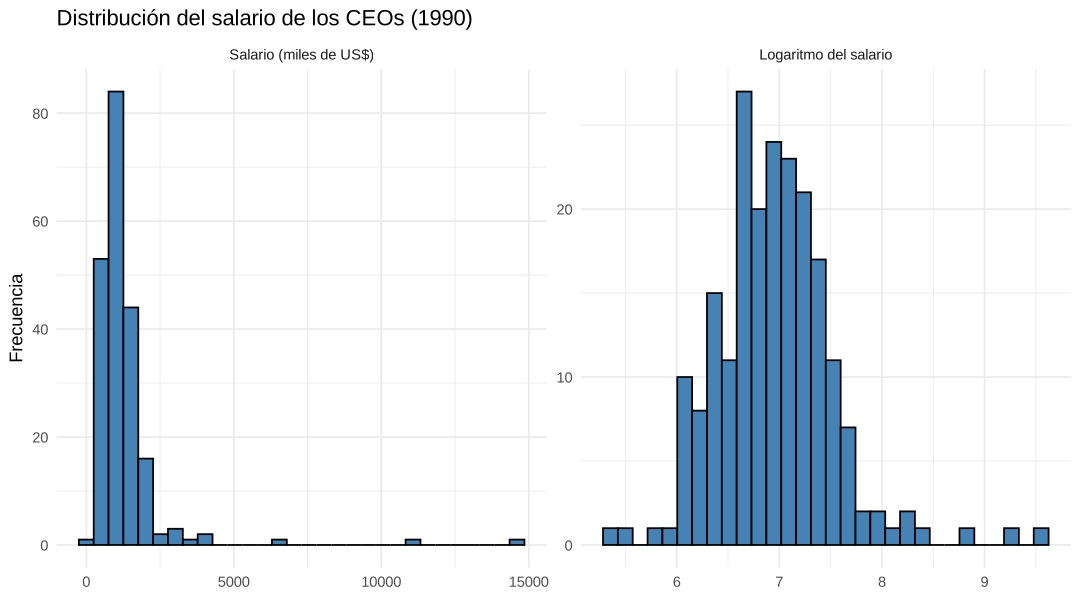

In [7]:
# Histogramas del salario en niveles y en logaritmo, uno al lado del otro
ceo %>%
  select(salary, lsalary) %>%
  pivot_longer(everything(),
               names_to = "variable", values_to = "valor") %>%
  mutate(variable = dplyr::recode(variable,
                                  salary  = "Salario (miles de US$)",
                                  lsalary = "Logaritmo del salario"),
         variable = factor(variable,
                           levels = c("Salario (miles de US$)",
                                      "Logaritmo del salario"))) %>%
  ggplot(aes(x = valor)) +
  geom_histogram(bins = 30, fill = "steelblue", color = "black") +
  facet_wrap(~ variable, scales = "free") +
  labs(title = "Distribución del salario de los CEOs (1990)",
       x = NULL, y = "Frecuencia") +
  theme_minimal()

En niveles, el salario se concentra bajo los 2 000 miles de dólares y presenta una cola larga a la derecha, con dos CEOs que superan los 10 000 miles de dólares. En logaritmo la distribución es aproximadamente simétrica y de forma acampanada. Esta es la principal razón para modelar `lsalary` en vez de `salary`.

### 3.2 Distribución de las ventas: niveles y logaritmo

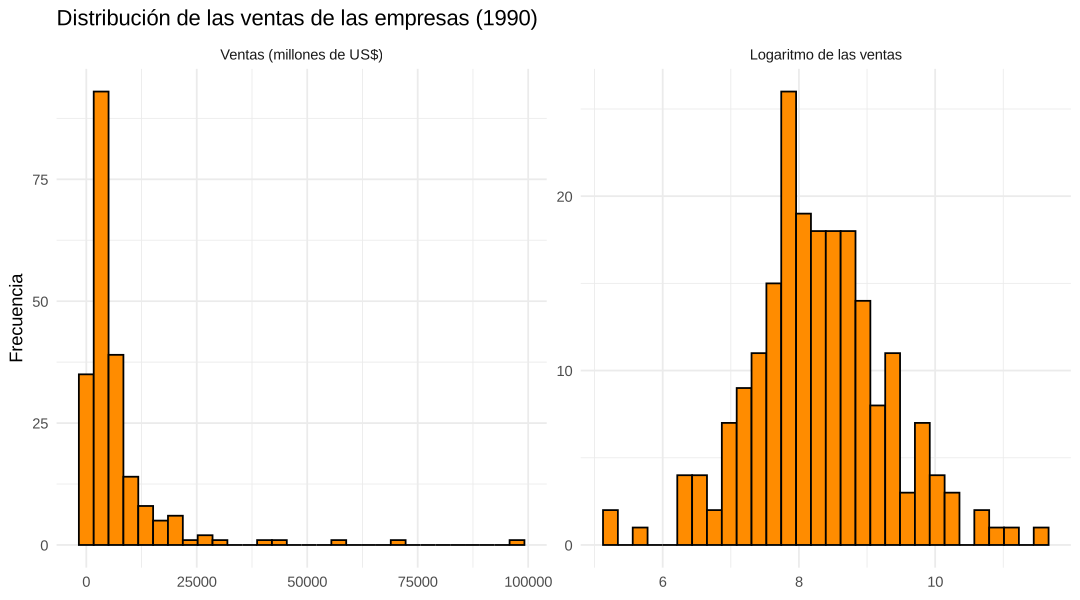

In [8]:
ceo %>%
  select(sales, lsales) %>%
  pivot_longer(everything(),
               names_to = "variable", values_to = "valor") %>%
  mutate(variable = dplyr::recode(variable,
                                  sales  = "Ventas (millones de US$)",
                                  lsales = "Logaritmo de las ventas"),
         variable = factor(variable,
                           levels = c("Ventas (millones de US$)",
                                      "Logaritmo de las ventas"))) %>%
  ggplot(aes(x = valor)) +
  geom_histogram(bins = 30, fill = "darkorange", color = "black") +
  facet_wrap(~ variable, scales = "free") +
  labs(title = "Distribución de las ventas de las empresas (1990)",
       x = NULL, y = "Frecuencia") +
  theme_minimal()

Las ventas tienen una asimetría aún más fuerte que el salario: la mayoría de las empresas vende menos de USD 10 000 millones, pero algunas superan los USD 50 000 millones. En logaritmo la distribución es casi simétrica, por lo que el tamaño de la empresa se incorpora como `lsales`.

### 3.3 Salario y tamaño de la empresa

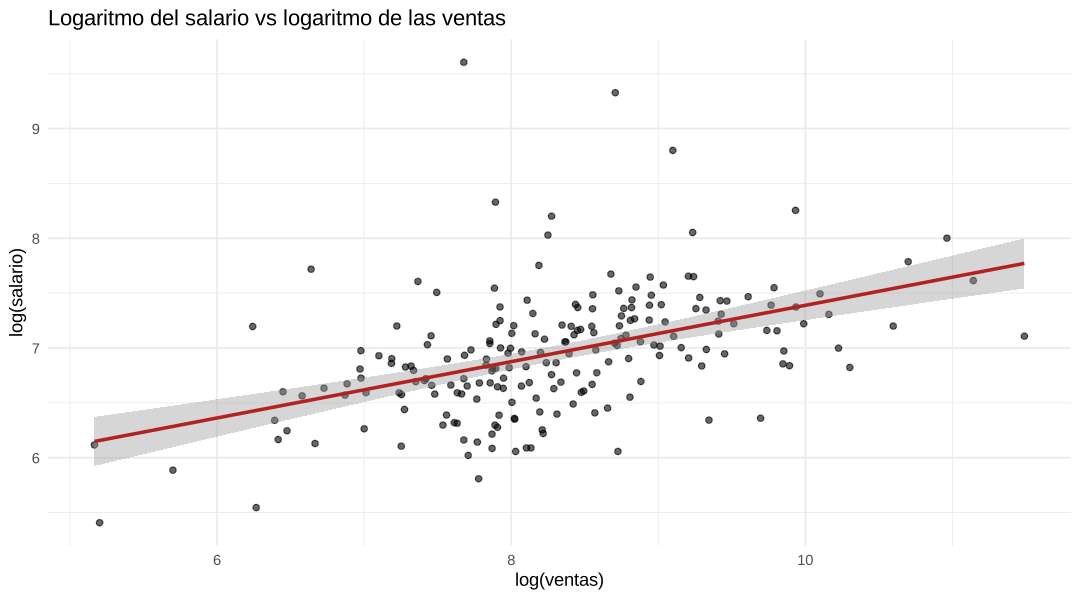

In [9]:
ggplot(ceo, aes(x = lsales, y = lsalary)) +
  geom_point(alpha = 0.6) +
  geom_smooth(method = "lm", formula = y ~ x, se = TRUE,
              color = "firebrick") +
  labs(title = "Logaritmo del salario vs logaritmo de las ventas",
       x = "log(ventas)", y = "log(salario)") +
  theme_minimal()

Se observa una relación positiva y aproximadamente lineal entre `lsales` y `lsalary`: las empresas más grandes pagan salarios más altos. Como ambas variables están en logaritmo, la pendiente de esta relación se interpreta como una **elasticidad**, lo que justifica la forma funcional log-log para el tamaño.

### 3.4 Salario y desempeño contable (ROE)

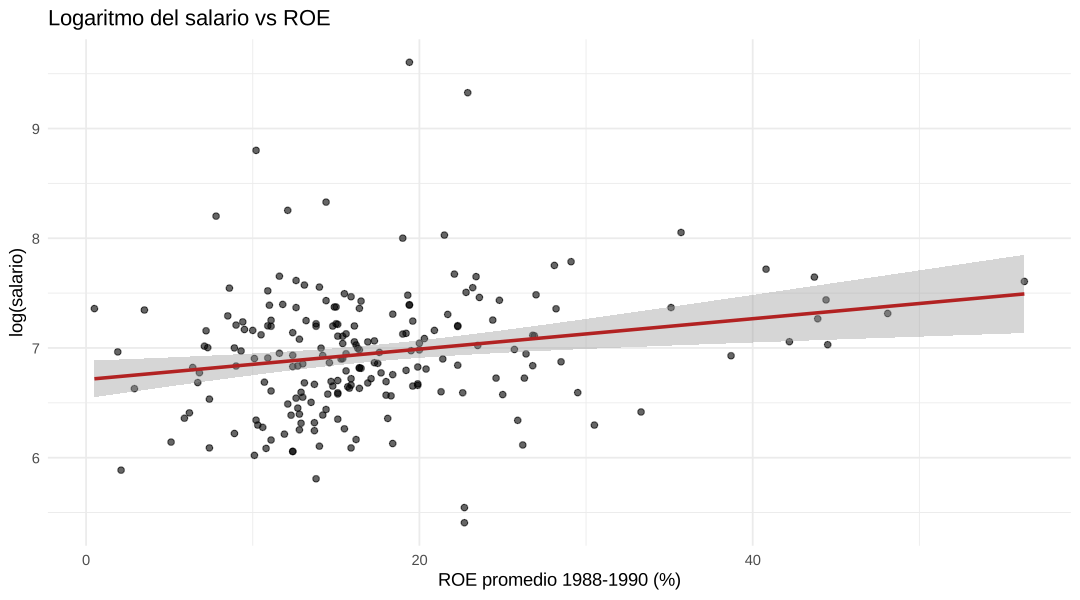

In [10]:
ggplot(ceo, aes(x = roe, y = lsalary)) +
  geom_point(alpha = 0.6) +
  geom_smooth(method = "lm", formula = y ~ x, se = TRUE,
              color = "firebrick") +
  labs(title = "Logaritmo del salario vs ROE",
       x = "ROE promedio 1988-1990 (%)", y = "log(salario)") +
  theme_minimal()

La relación entre ROE y salario es positiva pero con mucha dispersión alrededor de la recta, coherente con la correlación de 0,21. La mayoría de las empresas tiene un ROE entre 10 % y 25 %.

### 3.5 Salario y desempeño bursátil (rentabilidad de la acción)

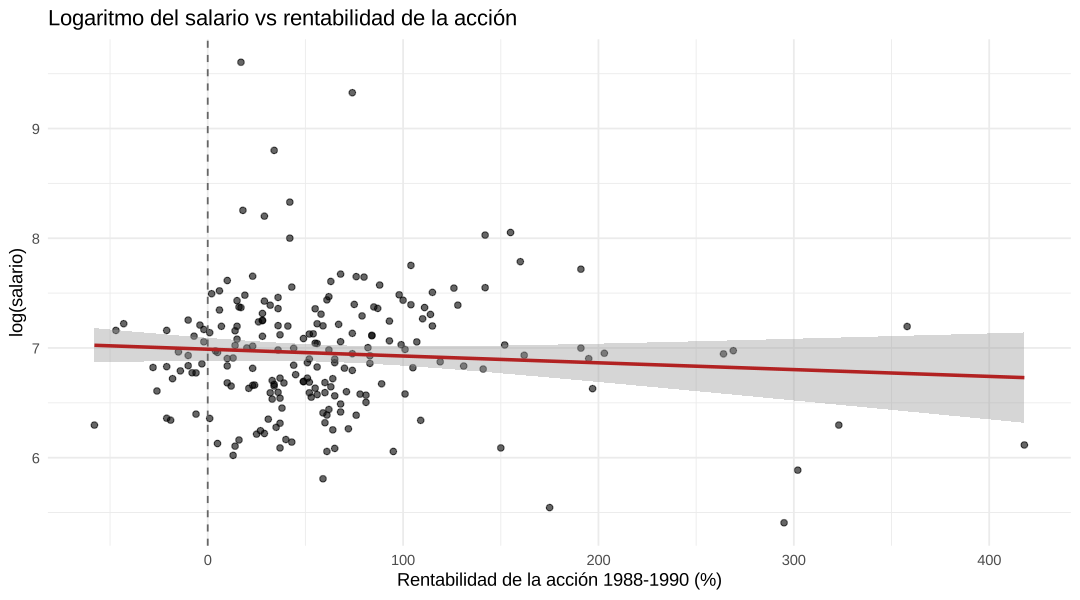

In [11]:
ggplot(ceo, aes(x = ros, y = lsalary)) +
  geom_point(alpha = 0.6) +
  geom_smooth(method = "lm", formula = y ~ x, se = TRUE,
              color = "firebrick") +
  geom_vline(xintercept = 0, linetype = "dashed", color = "grey40") +
  labs(title = "Logaritmo del salario vs rentabilidad de la acción",
       x = "Rentabilidad de la acción 1988-1990 (%)",
       y = "log(salario)") +
  theme_minimal()

La recta es prácticamente plana: en la relación simple, el salario no parece responder a la rentabilidad bursátil. Hay empresas con rentabilidad negativa (a la izquierda de la línea punteada) y algunas con rentabilidades sobre 200 %. El modelo múltiple permitirá ver si esta ausencia de relación se mantiene al controlar por tamaño y sector.

### 3.6 Salario según sector

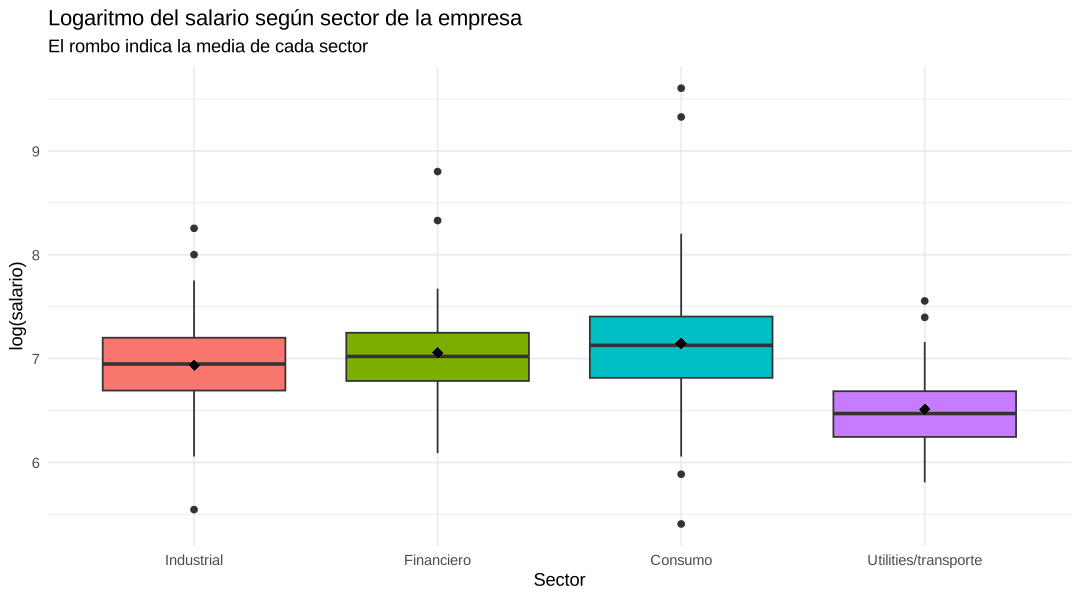

In [12]:
ggplot(ceo, aes(x = sector, y = lsalary, fill = sector)) +
  geom_boxplot(show.legend = FALSE) +
  stat_summary(fun = mean, geom = "point", shape = 18, size = 3,
               show.legend = FALSE) +
  labs(title = "Logaritmo del salario según sector de la empresa",
       subtitle = "El rombo indica la media de cada sector",
       x = "Sector", y = "log(salario)") +
  theme_minimal()

Las cajas de los sectores industrial, financiero y de consumo se ubican en niveles similares, con el sector consumo ligeramente más alto. La caja de servicios públicos y transporte está claramente más abajo: su mediana es menor que el primer cuartil de los demás sectores. Esta diferencia motiva incluir las dummies de sector y plantear una hipótesis específica sobre las empresas reguladas (sección 4.5).

### 3.7 Valores atípicos

In [13]:
# Las cinco remuneraciones más altas de la muestra
top5 <- ceo[order(-ceo$salary),
            c("salary", "sales", "roe", "ros", "sector")]
head(top5, 5)

# Número de observaciones fuera de 1,5 RIC en cada variable
fuera_ric <- function(x) {
  q <- quantile(x, c(0.25, 0.75)); r <- IQR(x)
  sum(x < q[1] - 1.5 * r | x > q[2] + 1.5 * r)
}
sapply(ceo[, c("salary", "lsalary", "sales", "lsales", "roe", "ros")],
       fuera_ric)

,salary,sales,roe,ros,sector
,<int>,<dbl>,<dbl>,<int>,<fct>
174,14822,2159.2,19.4,17,Consumo
164,11233,6047.9,22.9,74,Consumo
108,6640,8946.0,10.2,34,Financiero
87,4143,2678.4,14.4,42,Financiero
28,3844,20604.0,12.1,18,Industrial


salary lsalary   sales  lsales     roe     ros 
      9       7      21       7      13      13

El salario más alto (14 822 miles de dólares) corresponde a una empresa de bienes de consumo con ventas relativamente bajas (USD 2 159 millones), y es más de 14 veces la mediana. En niveles, 9 salarios y 21 valores de ventas quedan fuera del rango de 1,5 RIC; en logaritmo la cantidad baja a 7 en ambas variables. Se trata de datos reales, no de errores, por lo que se mantienen en la muestra; usar logaritmos reduce su influencia en la estimación.

## 4. Planteamiento del modelo e hipótesis de investigación

### 4.1 Pregunta de investigación

La teoría de agencia plantea que los accionistas (el principal) no pueden observar directamente el esfuerzo del CEO (el agente), por lo que conviene vincular su remuneración con resultados observables de la empresa para alinear incentivos (Jensen y Murphy, 1990). Al mismo tiempo, la literatura muestra que el principal determinante del salario de los ejecutivos es el **tamaño de la empresa**: firmas más grandes requieren y atraen a ejecutivos más capaces y les pagan más (Rosen, 1982; Gabaix y Landier, 2008).

Este trabajo busca responder: **¿se asocia el salario del CEO con el desempeño de su empresa, medido por la rentabilidad contable (ROE) y por la rentabilidad bursátil, manteniendo constante el tamaño de la firma y su sector?**

### 4.2 Variable dependiente

Se utiliza **`lsalary`**, el logaritmo natural del salario del CEO en 1990, por tres razones:

1. **Es la variable que mide el fenómeno de interés**: la remuneración del CEO.
2. **Distribución:** `salary` tiene asimetría 6,9 y valores extremos (sección 2.1 y gráfico 3.1). En logaritmo la asimetría baja a 0,88 y media y mediana coinciden, lo que reduce la influencia de los valores atípicos.
3. **Interpretación:** con el salario en logaritmo, los coeficientes se leen como cambios porcentuales, más comparables entre CEOs que ganan montos muy distintos. Es la especificación usual en la literatura de remuneración de ejecutivos y la que usa Wooldridge con esta base.

### 4.3 Variables explicativas

| Variable | Rol | Justificación |
|---|---|---|
| `lsales` | Tamaño de la empresa | Las empresas grandes pagan más (Rosen, 1982; Gabaix y Landier, 2008). Es la variable más correlacionada con el salario (0,46). En logaritmo su coeficiente es una elasticidad y se corrige la fuerte asimetría de `sales`. |
| `roe` | Desempeño contable (variable de interés) | Mide la rentabilidad que la empresa genera para sus accionistas. Si la remuneración premia el desempeño, debería asociarse positivamente con el salario. |
| `ros` | Desempeño bursátil (variable de interés) | Mide el retorno que obtuvieron los accionistas en el mercado. Según la teoría de agencia, es la medida de desempeño más directamente ligada a la riqueza de los accionistas (Jensen y Murphy, 1990). |
| `finance`, `consprod`, `utility` | Controles de sector | El salario medio difiere fuertemente entre sectores (sección 2.2). Las empresas de servicios públicos están reguladas, lo que limita sus remuneraciones (Joskow, Rose y Shepard, 1993). Se omite `indus` para evitar multicolinealidad perfecta: el sector **industrial** es la categoría base. |

**Variables no incluidas:**

- `salary` y `sales` en niveles: se reemplazan por sus logaritmos por las razones anteriores.
- `pcsalary`: es la variación del propio salario, por lo que no explica el nivel del salario sino que deriva de él.
- `pcroe`: mide el cambio en el ROE y no su nivel; además tiene valores extremos (hasta 977 %) generados por empresas que partían de un ROE cercano a cero.

### 4.4 Modelo de regresión poblacional

Se propone el siguiente Modelo de Regresión Lineal Múltiple:

$$
\begin{aligned}
\log(salary_i) = {} & \beta_0 + \beta_1 \log(sales_i) + \beta_2\, roe_i + \beta_3\, ros_i \\
& + \beta_4\, finance_i + \beta_5\, consprod_i + \beta_6\, utility_i + u_i
\end{aligned}
$$

donde $i = 1, \dots, 209$ indexa a los CEOs y $u_i$ es el término de error, que recoge los factores no observados que afectan el salario (por ejemplo, la experiencia o la antigüedad del CEO).

**Interpretación de los parámetros y signo esperado**

| Parámetro | Interpretación (*ceteris paribus*) | Signo esperado |
|---|---|---|
| $\beta_1$ | Elasticidad salario–ventas: un aumento de 1 % en las ventas se asocia con un cambio de $\beta_1$ % en el salario. | $+$ (entre 0 y 1) |
| $\beta_2$ | Un punto porcentual más de ROE se asocia con un cambio de aproximadamente $100\cdot\beta_2$ % en el salario. | $+$ |
| $\beta_3$ | Un punto porcentual más de rentabilidad de la acción se asocia con un cambio de aproximadamente $100\cdot\beta_3$ % en el salario. | $+$ |
| $\beta_4$ | Diferencia porcentual aproximada del salario de un CEO financiero respecto de uno industrial. | $\pm$ |
| $\beta_5$ | Diferencia porcentual aproximada del salario de un CEO de bienes de consumo respecto de uno industrial. | $+$ |
| $\beta_6$ | Diferencia porcentual aproximada del salario de un CEO de servicios públicos o transporte respecto de uno industrial. | $-$ |

Se espera que $\beta_1$ sea menor que 1 porque el salario crece con el tamaño de la empresa, pero menos que proporcionalmente.

### 4.5 Hipótesis de investigación

Las hipótesis se plantean sobre los parámetros del modelo poblacional, se contrastan en la sección 8 con el modelo corregido y se evalúan con un nivel de significancia del 5 %.

**H1 — Tamaño:** a mayor tamaño de la empresa, mayor es el salario del CEO.
$$H_0: \beta_1 = 0 \quad \text{vs.} \quad H_1: \beta_1 > 0$$

**H2 — Desempeño contable:** un mayor ROE se asocia con un mayor salario del CEO, manteniendo constantes el tamaño, la rentabilidad bursátil y el sector.
$$H_0: \beta_2 = 0 \quad \text{vs.} \quad H_1: \beta_2 > 0$$

**H3 — Desempeño bursátil:** una mayor rentabilidad de la acción se asocia con un mayor salario del CEO, manteniendo constantes el tamaño, el ROE y el sector.
$$H_0: \beta_3 = 0 \quad \text{vs.} \quad H_1: \beta_3 > 0$$

**H4 — Desempeño en conjunto:** las medidas de desempeño, en conjunto, ayudan a explicar el salario del CEO (prueba F de significancia conjunta).
$$H_0: \beta_2 = \beta_3 = 0 \quad \text{vs.} \quad H_1: \text{al menos uno de } \beta_2, \beta_3 \text{ es distinto de } 0$$

**H5 — Sector regulado:** los CEOs de empresas de servicios públicos y transporte ganan menos que los de empresas industriales de igual tamaño y desempeño.
$$H_0: \beta_6 = 0 \quad \text{vs.} \quad H_1: \beta_6 < 0$$

H1 a H3 y H5 se contrastan con pruebas *t* de una cola y H4 con una prueba *F*. Las hipótesis H2 a H4 responden directamente a la pregunta de investigación; H1 y H5 verifican que el modelo recoja los determinantes conocidos del salario de los ejecutivos.

## 5. Estimación del modelo

El modelo poblacional de la sección 4.4 se estima por Mínimos Cuadrados Ordinarios (MCO) con la función `lm()`. Todos los coeficientes se interpretan *ceteris paribus*, es decir, manteniendo constantes las demás variables del modelo.

In [14]:
# ============================================================
# 5. Estimación del modelo por MCO
# ============================================================

# lm() estima el modelo por MCO; summary() muestra coeficientes,
# errores estándar, estadísticos t, p-valores, R2 y prueba F global
modelo <- lm(lsalary ~ lsales + roe + ros + finance + consprod + utility,
             data = ceo)
summary(modelo)


Call:
lm(formula = lsalary ~ lsales + roe + ros + finance + consprod + 
    utility, data = ceo)

Residuals:
     Min       1Q   Median       3Q      Max 
-1.09373 -0.22509 -0.02252  0.17118  2.63906 

Coefficients:
              Estimate Std. Error t value Pr(>|t|)    
(Intercept)  4.599e+00  3.157e-01  14.567  < 2e-16 ***
lsales       2.560e-01  3.420e-02   7.487 2.15e-12 ***
roe          1.121e-02  4.351e-03   2.576  0.01070 *  
ros         -5.355e-05  5.432e-04  -0.099  0.92158    
finance      1.585e-01  8.938e-02   1.773  0.07771 .  
consprod     1.835e-01  8.915e-02   2.059  0.04079 *  
utility     -2.822e-01  9.981e-02  -2.827  0.00516 ** 
---
Signif. codes:  0 ‘***’ 0.001 ‘**’ 0.01 ‘*’ 0.05 ‘.’ 0.1 ‘ ’ 1

Residual standard error: 0.4609 on 202 degrees of freedom
Multiple R-squared:  0.3569,	Adjusted R-squared:  0.3378 
F-statistic: 18.68 on 6 and 202 DF,  p-value: < 2.2e-16


In [15]:
# Tabla ordenada de coeficientes
coefs <- summary(modelo)$coefficients
tabla_mco <- data.frame(Coeficiente    = coefs[, 1],
                        Error_estandar = coefs[, 2],
                        t              = coefs[, 3],
                        p_valor        = coefs[, 4])
round(tabla_mco, 5)

# Efecto porcentual exacto de las dummies de sector: 100 * (exp(b) - 1)
dummies_sector <- c("finance", "consprod", "utility")
round(100 * (exp(coef(modelo)[dummies_sector]) - 1), 1)

,Coeficiente,Error_estandar,t,p_valor
,<dbl>,<dbl>,<dbl>,<dbl>
(Intercept),4.59899,0.31572,14.56667,0.00000
lsales,0.25603,0.03420,7.48655,0.00000
roe,0.01121,0.00435,2.57643,0.01070
ros,-0.00005,0.00054,-0.09857,0.92158
finance,0.15849,0.08938,1.77315,0.07771
consprod,0.18355,0.08915,2.05891,0.04079
utility,-0.28220,0.09981,-2.82743,0.00516


finance consprod  utility 
    17.2     20.1    -24.6

### 5.1 Interpretación de los coeficientes

- **Tamaño (`lsales`): 0.256.** Es la elasticidad salario–ventas: un aumento de 10 % en las ventas se asocia con un salario del CEO 2.56 % mayor, manteniendo constantes la rentabilidad y el sector. El signo es el esperado, la magnitud está entre 0 y 1 (el salario crece menos que proporcionalmente con el tamaño) y es altamente significativa (t = 7.49).
- **ROE (`roe`): 0.0112.** Un punto porcentual más de ROE se asocia con un salario aproximadamente 1.12 % mayor. Un aumento de una desviación estándar del ROE (8.5 puntos) equivale a un salario cerca de 10 % mayor. Es significativo al 5 % (p = 0.011).
- **Rentabilidad de la acción (`ros`): −0.00005.** El coeficiente es prácticamente cero y no significativo (p = 0.92): incluso un aumento de 100 puntos porcentuales en la rentabilidad bursátil se asocia con un cambio de apenas −0.5 % en el salario.
- **Sector financiero (`finance`): 0.158.** Los CEOs de empresas financieras ganan cerca de 17 % más que los de empresas industriales con igual tamaño y rentabilidad (100·(e^0.158 − 1)), pero la diferencia solo es significativa al 10 % (p = 0.078).
- **Bienes de consumo (`consprod`): 0.184.** Los CEOs de este sector ganan cerca de 20 % más que los del sector industrial (p = 0.041).
- **Servicios públicos y transporte (`utility`): −0.282.** Los CEOs de empresas reguladas ganan cerca de 25 % menos que los del sector industrial, con igual tamaño y rentabilidad (p = 0.005).
- **Intercepto: 4.60.** No tiene una interpretación económica directa, porque corresponde a una empresa industrial con ventas de 1 millón de dólares (log = 0) y rentabilidad nula, situación fuera del rango de la muestra.

### 5.2 Bondad de ajuste

El $R^2$ es 0.357 y el $R^2$ ajustado 0.338: el modelo explica alrededor del 36 % de la variación del logaritmo del salario. Es un valor razonable para datos de corte transversal sobre remuneraciones, donde influyen muchos factores no observados (habilidad, antigüedad y edad del CEO, gobierno corporativo de la empresa). La prueba F de significancia global (F = 18.68, p < 0.001) rechaza que todos los coeficientes sean cero.

## 6. Verificación de los supuestos del modelo

Se evalúan los supuestos del Modelo de Regresión Lineal Múltiple que exigen las instrucciones: exogeneidad, homocedasticidad, normalidad de los errores y ausencia de multicolinealidad severa.

### 6.1 Exogeneidad

El supuesto de exogeneidad exige

$$E(u_i \mid lsales_i, roe_i, ros_i, finance_i, consprod_i, utility_i) = 0,$$

es decir, que los factores no observados que afectan el salario no estén correlacionados con los regresores. Este supuesto no puede comprobarse con una prueba estadística directa, porque el error no se observa; se evalúa con argumentos económicos y con pruebas indirectas.

**Amenazas desde la teoría económica:**

1. **Variables omitidas.** La base no incluye características del CEO como la habilidad, la experiencia, la antigüedad en el cargo o la edad. Es probable que los CEOs más capaces dirijan empresas más grandes y más rentables, de modo que `lsales` y `roe` estarían correlacionados con el error y sus coeficientes podrían estar sesgados hacia arriba.
2. **Simultaneidad.** El desempeño de la empresa depende en parte del propio CEO, y un salario alto puede atraer a mejores ejecutivos que luego mejoran la rentabilidad. La causalidad podría ir en ambas direcciones.
3. **Forma funcional.** Si la relación verdadera no es lineal en los parámetros elegidos, la parte omitida queda en el error. Esto sí se puede evaluar con la prueba RESET de Ramsey.

Por estas razones, los resultados se interpretan como **asociaciones condicionales**, no como efectos causales.

In [16]:
# ============================================================
# 6.1 Exogeneidad
# ============================================================

# Por construcción, los residuos de MCO no están correlacionados con
# los regresores. Esto NO prueba la exogeneidad; solo se muestra
# para dejar claro que el supuesto no puede verificarse así.
round(cor(residuals(modelo), ceo[, c("lsales", "roe", "ros")]), 4)

# Prueba RESET de Ramsey (H0: la forma funcional es correcta).
# Agrega los valores ajustados al cuadrado y al cubo al modelo.
resettest(modelo, power = 2:3, type = "fitted")

lsales,roe,ros
0,0,0



	RESET test

data:  modelo
RESET = 6.3325, df1 = 2, df2 = 200, p-value = 0.002155


La correlación entre residuos y regresores es cero por construcción del método, por lo que no aporta evidencia sobre la exogeneidad. La prueba RESET (F = 6.33, p = 0.002) **rechaza** que la forma funcional sea correcta: hay alguna no linealidad que el modelo no recoge. En la sección 9.2 se estima una especificación alternativa con un término cuadrático del tamaño para evaluar si esto cambia las conclusiones.

### 6.2 Homocedasticidad

Se evalúa si la varianza del error es constante. La hipótesis nula de las pruebas de Breusch-Pagan y de White es homocedasticidad. Breusch-Pagan regresiona los residuos al cuadrado sobre los regresores; White agrega sus cuadrados e interacciones.


	studentized Breusch-Pagan test

data:  modelo
BP = 7.2831, df = 6, p-value = 0.2955



	studentized Breusch-Pagan test

data:  modelo
BP = 12.081, df = 21, p-value = 0.9374


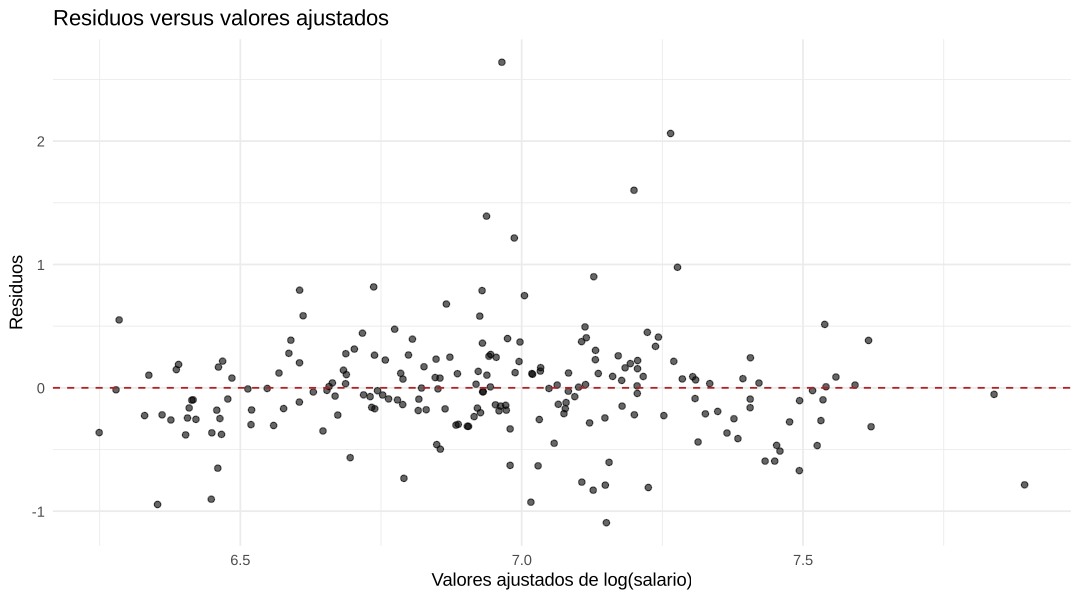

In [17]:
# ============================================================
# 6.2 Homocedasticidad
# ============================================================

# Gráfico de residuos versus valores ajustados
diag_df <- data.frame(ajustados = fitted(modelo),
                      residuos  = residuals(modelo))
ggplot(diag_df, aes(x = ajustados, y = residuos)) +
  geom_point(alpha = 0.6) +
  geom_hline(yintercept = 0, color = "firebrick", linetype = "dashed") +
  labs(title = "Residuos versus valores ajustados",
       x = "Valores ajustados de log(salario)", y = "Residuos") +
  theme_minimal()

# Prueba de Breusch-Pagan
bptest(modelo)

# Prueba de White: regresores, sus cuadrados y sus interacciones
# (las interacciones entre dummies de sector se omiten porque son
# siempre cero: una empresa pertenece a un solo sector)
white <- bptest(modelo,
  ~ lsales + roe + ros + finance + consprod + utility +
    I(lsales^2) + I(roe^2) + I(ros^2) +
    lsales:roe + lsales:ros + roe:ros +
    lsales:finance + lsales:consprod + lsales:utility +
    roe:finance + roe:consprod + roe:utility +
    ros:finance + ros:consprod + ros:utility,
  data = ceo)
white

Ninguna prueba rechaza la homocedasticidad: Breusch-Pagan entrega BP = 7.28 con p = 0.296 y White entrega 12.08 con p = 0.937. En el gráfico, los residuos se distribuyen alrededor de cero con una dispersión parecida a lo largo de los valores ajustados; solo destacan unos pocos residuos positivos grandes, que corresponden a CEOs con salarios muy por encima de lo que predice el modelo (sección 6.3). No hay evidencia de heterocedasticidad, por lo que los errores estándar de MCO son válidos.

### 6.3 Normalidad de los errores

Se evalúa con las pruebas de Jarque-Bera y Shapiro-Wilk (H0: los errores son normales) y con un gráfico QQ, que compara los cuantiles de los residuos con los de una distribución normal.


	Jarque Bera Test

data:  residuals(modelo)
X-squared = 560.24, df = 2, p-value < 2.2e-16



	Shapiro-Wilk normality test

data:  residuals(modelo)
W = 0.88575, p-value = 1.703e-11


,salary,sales,roe,ros,sector,residuo_est
,<int>,<dbl>,<dbl>,<int>,<fct>,<dbl>
87,4143,2678.4,14.4,42,Financiero,3.06
108,6640,8946.0,10.2,34,Financiero,3.52
164,11233,6047.9,22.9,74,Consumo,4.51
174,14822,2159.2,19.4,17,Consumo,5.82


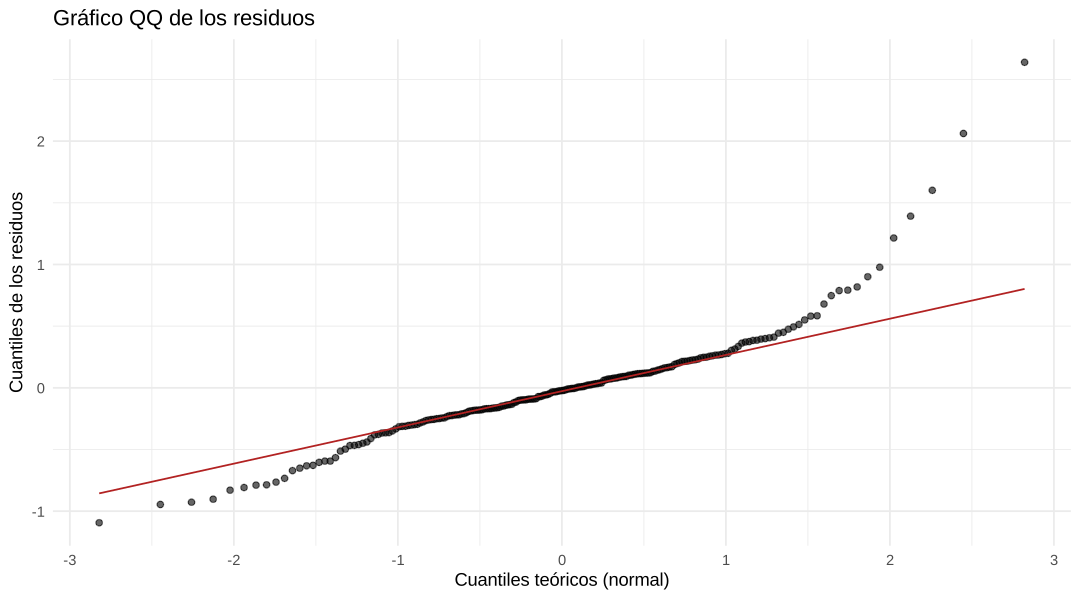

In [18]:
# ============================================================
# 6.3 Normalidad
# ============================================================

jarque.bera.test(residuals(modelo))
shapiro.test(residuals(modelo))

# Gráfico QQ de los residuos
ggplot(data.frame(residuos = residuals(modelo)), aes(sample = residuos)) +
  stat_qq(alpha = 0.6) +
  stat_qq_line(color = "firebrick") +
  labs(title = "Gráfico QQ de los residuos",
       x = "Cuantiles teóricos (normal)",
       y = "Cuantiles de los residuos") +
  theme_minimal()

# Observaciones con residuo estandarizado mayor que 3 en valor absoluto
res_est <- rstandard(modelo)
cbind(ceo[abs(res_est) > 3, c("salary", "sales", "roe", "ros", "sector")],
      residuo_est = round(res_est[abs(res_est) > 3], 2))

Ambas pruebas **rechazan** la normalidad (Jarque-Bera = 560.2 y Shapiro-Wilk W = 0.886, ambas con p < 0.001). El gráfico QQ muestra que el problema está en la cola derecha: los puntos se alejan de la recta en los residuos más altos. Cuatro CEOs tienen residuos estandarizados mayores que 3, entre ellos los dos salarios más altos de la muestra (14 822 y 11 233 miles de dólares, ambos del sector consumo).

La normalidad no es necesaria para que MCO sea insesgado ni consistente; se usa para que las pruebas *t* y *F* sean exactas en muestras pequeñas. Con 209 observaciones, por el teorema del límite central los estimadores se distribuyen aproximadamente normal, de modo que la inferencia es válida de forma asintótica. Aun así, en la sección 9.1 se verifica que los resultados no dependen de estos cuatro valores atípicos.

### 6.4 Multicolinealidad

Se calcula el Factor de Inflación de la Varianza (VIF) de cada regresor. Un VIF mayor que 10 suele indicar multicolinealidad severa; valores cercanos a 1 indican que el regresor está poco relacionado con los demás.

In [19]:
# ============================================================
# 6.4 Multicolinealidad
# ============================================================

round(vif(modelo), 3)

lsales      roe      ros  finance consprod  utility 
   1.176    1.345    1.343    1.349    1.600    1.397

Todos los VIF están entre 1.18 y 1.60, muy por debajo de 10. El mayor corresponde a `consprod`, coherente con su correlación de 0.41 con `roe` vista en la sección 2.3. No hay multicolinealidad que afecte la precisión de las estimaciones, por lo que no es necesario eliminar variables.

## 7. Correcciones

Resumen del diagnóstico:

| Supuesto | Prueba | Resultado |
|---|---|---|
| Exogeneidad | Argumentos económicos y RESET | Posibles variables omitidas; RESET rechaza la forma funcional (p = 0.002) |
| Homocedasticidad | Breusch-Pagan y White | No se rechaza (p = 0.296 y p = 0.937) |
| Normalidad | Jarque-Bera, Shapiro-Wilk y QQ | Se rechaza (p < 0.001), por cuatro valores atípicos |
| Multicolinealidad | VIF | Sin problemas (VIF máximo 1.60) |

Aunque las pruebas no detectan heterocedasticidad, se adopta una postura conservadora: la inferencia se realiza con **errores estándar robustos HC1** (White, 1980). Esta corrección no cambia los coeficientes, solo los errores estándar, y es válida tanto si hay heterocedasticidad como si no la hay; además es menos sensible a los valores atípicos. Los problemas de valores atípicos y de forma funcional se abordan en la sección 9 como análisis de robustez.

In [20]:
# ============================================================
# 7. Corrección: errores estándar robustos HC1
# ============================================================

# vcovHC() calcula la matriz de varianzas robusta y coeftest()
# recalcula los estadísticos t y los p-valores con ella
vcov_hc1 <- vcovHC(modelo, type = "HC1")
robusto <- coeftest(modelo, vcov = vcov_hc1)
robusto

# Comparación de errores estándar y p-valores: MCO vs robustos
comparacion <- data.frame(Coeficiente = coef(modelo),
                          EE_MCO      = sqrt(diag(vcov(modelo))),
                          EE_robusto  = sqrt(diag(vcov_hc1)),
                          p_MCO       = coefs[, 4],
                          p_robusto   = robusto[, 4])
round(comparacion, 5)


t test of coefficients:

               Estimate  Std. Error t value  Pr(>|t|)    
(Intercept)  4.5990e+00  3.0946e-01 14.8612 < 2.2e-16 ***
lsales       2.5603e-01  3.3903e-02  7.5519 1.452e-12 ***
roe          1.1211e-02  4.1654e-03  2.6913 0.0077128 ** 
ros         -5.3545e-05  6.3195e-04 -0.0847 0.9325597    
finance      1.5849e-01  8.3017e-02  1.9091 0.0576674 .  
consprod     1.8355e-01  1.0930e-01  1.6794 0.0946251 .  
utility     -2.8220e-01  7.3841e-02 -3.8217 0.0001764 ***
---
Signif. codes:  0 ‘***’ 0.001 ‘**’ 0.01 ‘*’ 0.05 ‘.’ 0.1 ‘ ’ 1


,Coeficiente,EE_MCO,EE_robusto,p_MCO,p_robusto
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
(Intercept),4.59899,0.31572,0.30946,0.00000,0.00000
lsales,0.25603,0.03420,0.03390,0.00000,0.00000
roe,0.01121,0.00435,0.00417,0.01070,0.00771
ros,-0.00005,0.00054,0.00063,0.92158,0.93256
finance,0.15849,0.08938,0.08302,0.07771,0.05767
consprod,0.18355,0.08915,0.10930,0.04079,0.09463
utility,-0.28220,0.09981,0.07384,0.00516,0.00018


Con errores robustos, los coeficientes de `lsales` (t = 7.55), `roe` (t = 2.69, p = 0.008) y `utility` (t = −3.82, p < 0.001) siguen siendo significativos al 5 %, y `ros` sigue sin serlo (p = 0.93). El cambio más notorio es en `consprod`, cuyo error estándar aumenta de 0.089 a 0.109 y deja de ser significativo al 5 % (p = 0.095): parte de su significancia dependía de los dos salarios extremos del sector consumo. `finance` queda en el límite (p = 0.058). Este es el **modelo corregido** con el que se testean las hipótesis.

## 8. Testeo de las hipótesis de investigación

Las hipótesis H1, H2, H3 y H5 se contrastan con pruebas *t* de una cola usando los estadísticos *t* robustos. Para una alternativa "mayor que cero" el p-valor es $P(t_{202} > t)$, y para "menor que cero" es $P(t_{202} < t)$. H4 se contrasta con una prueba *F* robusta de significancia conjunta.

In [21]:
# ============================================================
# 8. Testeo de hipótesis con el modelo corregido (HC1)
# ============================================================

gl <- modelo$df.residual          # grados de libertad: n - k - 1 = 202
t_rob <- robusto[, "t value"]     # estadísticos t robustos

pruebas <- data.frame(
  Hipotesis  = c("H1: b_lsales > 0", "H2: b_roe > 0",
                 "H3: b_ros > 0", "H5: b_utility < 0"),
  t_robusto  = round(unname(t_rob[c("lsales", "roe", "ros",
                                    "utility")]), 3),
  p_una_cola = signif(c(pt(t_rob["lsales"], gl, lower.tail = FALSE),
                        pt(t_rob["roe"], gl, lower.tail = FALSE),
                        pt(t_rob["ros"], gl, lower.tail = FALSE),
                        pt(t_rob["utility"], gl, lower.tail = TRUE)), 3),
  row.names = NULL)
pruebas$Decision_5 <- ifelse(pruebas$p_una_cola < 0.05,
                             "Se rechaza H0", "No se rechaza H0")
pruebas

# H4: prueba F robusta de que roe y ros son conjuntamente cero
linearHypothesis(modelo, c("roe = 0", "ros = 0"), white.adjust = "hc1")

Hipotesis,t_robusto,p_una_cola,Decision_5
<chr>,<dbl>,<dbl>,<chr>
H1: b_lsales > 0,7.552,7.26e-13,Se rechaza H0
H2: b_roe > 0,2.691,3.86e-03,Se rechaza H0
H3: b_ros > 0,-0.085,5.34e-01,No se rechaza H0
H5: b_utility < 0,-3.822,8.82e-05,Se rechaza H0


,Res.Df,Df,F,Pr(>F)
,<dbl>,<dbl>,<dbl>,<dbl>
1,204,NA,NA,NA
2,202,2,3.675389,0.0270493


| Hipótesis | Estadístico | p-valor | Decisión (5 %) | Conclusión |
|---|---|---|---|---|
| H1: $\beta_1 > 0$ (tamaño) | t = 7.55 | < 0.001 | Se rechaza $H_0$ | Se confirma: las empresas más grandes pagan más a sus CEOs. |
| H2: $\beta_2 > 0$ (ROE) | t = 2.69 | 0.004 | Se rechaza $H_0$ | Se confirma: un mayor ROE se asocia con un mayor salario. |
| H3: $\beta_3 > 0$ (rentabilidad de la acción) | t = −0.08 | 0.534 | No se rechaza $H_0$ | No se confirma: no hay evidencia de que el salario responda al desempeño bursátil. |
| H4: $\beta_2 = \beta_3 = 0$ (desempeño conjunto) | F = 3.68 | 0.027 | Se rechaza $H_0$ | Se confirma: el desempeño, en conjunto, ayuda a explicar el salario. |
| H5: $\beta_6 < 0$ (sector regulado) | t = −3.82 | < 0.001 | Se rechaza $H_0$ | Se confirma: los CEOs de servicios públicos ganan menos. |

En síntesis, la respuesta a la pregunta de investigación es **parcialmente afirmativa**: el salario del CEO se asocia positivamente con el desempeño contable de la empresa (ROE), pero no con su desempeño en la bolsa. La significancia conjunta de H4 proviene del ROE. El tamaño de la empresa es, con diferencia, el factor más asociado al salario.

## 9. Análisis de robustez

### 9.1 Modelo sin valores atípicos

Se reestima el modelo excluyendo las cuatro observaciones con residuo estandarizado mayor que 3 (sección 6.3), para comprobar que las conclusiones no dependen de ellas.

In [22]:
# ============================================================
# 9.1 Robustez: modelo sin valores atípicos
# ============================================================

ceo_sin <- ceo[abs(res_est) <= 3, ]
nrow(ceo_sin)

modelo_sin <- lm(lsalary ~ lsales + roe + ros +
                   finance + consprod + utility, data = ceo_sin)
coeftest(modelo_sin, vcov = vcovHC(modelo_sin, type = "HC1"))
summary(modelo_sin)$r.squared

# La normalidad mejora mucho al excluir los valores atípicos
jarque.bera.test(residuals(modelo_sin))

[1] 205


t test of coefficients:

               Estimate  Std. Error t value  Pr(>|t|)    
(Intercept)  4.47287146  0.25410639 17.6024 < 2.2e-16 ***
lsales       0.26720002  0.02805816  9.5231 < 2.2e-16 ***
roe          0.01210241  0.00402627  3.0059 0.0029911 ** 
ros          0.00036180  0.00052991  0.6828 0.4955525    
finance      0.09024629  0.06986150  1.2918 0.1979362    
consprod     0.07415605  0.07975705  0.9298 0.3536202    
utility     -0.27975231  0.07317926 -3.8228 0.0001766 ***
---
Signif. codes:  0 ‘***’ 0.001 ‘**’ 0.01 ‘*’ 0.05 ‘.’ 0.1 ‘ ’ 1


[1] 0.4529445


	Jarque Bera Test

data:  residuals(modelo_sin)
X-squared = 11.83, df = 2, p-value = 0.002698


Sin los cuatro valores atípicos (n = 205), el $R^2$ sube de 0.357 a 0.453 y el estadístico de Jarque-Bera baja de 560 a 11.8: la falta de normalidad se debía casi por completo a esos cuatro CEOs. Las conclusiones sobre las hipótesis no cambian: `lsales` (0.267), `roe` (0.0121, p = 0.003) y `utility` (−0.280, p < 0.001) siguen siendo significativos, y `ros` sigue sin serlo (p = 0.50). En cambio, la prima de los sectores consumo y financiero desaparece (p = 0.35 y p = 0.20), lo que confirma que dependía de unos pocos salarios excepcionales.

### 9.2 Forma funcional: tamaño con efecto cuadrático

Como la prueba RESET rechazó la forma funcional, se agrega el término $\log(sales)^2$, que permite que la elasticidad salario–ventas cambie con el tamaño de la empresa.

In [23]:
# ============================================================
# 9.2 Robustez: término cuadrático del tamaño
# ============================================================

modelo_cuad <- lm(lsalary ~ lsales + I(lsales^2) + roe + ros +
                    finance + consprod + utility, data = ceo)
coeftest(modelo_cuad, vcov = vcovHC(modelo_cuad, type = "HC1"))
summary(modelo_cuad)$adj.r.squared

# ¿Mejora la forma funcional?
resettest(modelo_cuad, power = 2:3, type = "fitted")

# Elasticidad salario-ventas evaluada en el promedio de lsales
b <- coef(modelo_cuad)
b["lsales"] + 2 * b["I(lsales^2)"] * mean(ceo$lsales)

# Nivel de ventas (millones de USD) en que la elasticidad se hace cero
punto_max <- exp(-b["lsales"] / (2 * b["I(lsales^2)"]))
punto_max
sum(ceo$sales > punto_max)        # empresas sobre ese nivel

# H4 en el modelo cuadrático
linearHypothesis(modelo_cuad, c("roe = 0", "ros = 0"),
                 white.adjust = "hc1")


t test of coefficients:

               Estimate  Std. Error t value  Pr(>|t|)    
(Intercept)  0.18150587  1.41779576  0.1280 0.8982613    
lsales       1.32294988  0.33672110  3.9289 0.0001173 ***
I(lsales^2) -0.06326365  0.01994437 -3.1720 0.0017512 ** 
roe          0.00951822  0.00420357  2.2643 0.0246219 *  
ros          0.00059519  0.00067868  0.8770 0.3815397    
finance      0.10799029  0.08203326  1.3164 0.1895320    
consprod     0.17606200  0.10443057  1.6859 0.0933621 .  
utility     -0.35581272  0.07454446 -4.7732 3.486e-06 ***
---
Signif. codes:  0 ‘***’ 0.001 ‘**’ 0.01 ‘*’ 0.05 ‘.’ 0.1 ‘ ’ 1


[1] 0.3639662


	RESET test

data:  modelo_cuad
RESET = 3.3088, df1 = 2, df2 = 199, p-value = 0.03858


lsales 
0.2737519

lsales 
34746.86

[1] 5

,Res.Df,Df,F,Pr(>F)
,<dbl>,<dbl>,<dbl>,<dbl>
1,203,NA,NA,NA
2,201,2,2.849566,0.06021009


El término cuadrático es negativo y significativo (−0.063, p = 0.002): el salario crece con el tamaño de la empresa, pero cada vez menos. Evaluada en el tamaño promedio, la elasticidad es 0.27, prácticamente igual a la del modelo principal (0.26). El efecto del tamaño solo se anularía con ventas cercanas a 35 000 millones de dólares, nivel que solo superan 5 de las 209 empresas de la muestra. La prueba RESET mejora (p = 0.039), aunque sigue rechazando al 5 %.

Las conclusiones se mantienen: `roe` sigue siendo positivo y significativo (0.0095, p = 0.025), `ros` no es significativo (p = 0.38) y `utility` es negativo y significativo (−0.356, p < 0.001). La prueba conjunta de H4 queda en el límite (F = 2.85, p = 0.060), lo que indica que la evidencia sobre el desempeño descansa en el ROE.

### 9.3 Comparación de los tres modelos

In [24]:
# ============================================================
# 9.3 Comparación de coeficientes entre modelos (p-valores robustos)
# ============================================================

fila <- function(m, v) {
  r <- coeftest(m, vcov = vcovHC(m, type = "HC1"))
  p <- ifelse(r[v, 4] < 0.001, "p < 0.001", sprintf("p = %.3f", r[v, 4]))
  sprintf("%.4f (%s)", r[v, 1], p)
}
vars_interes <- c("roe", "ros", "finance", "consprod", "utility")

data.frame(
  Variable     = vars_interes,
  Principal    = sapply(vars_interes, function(v) fila(modelo, v)),
  Sin_atipicos = sapply(vars_interes, function(v) fila(modelo_sin, v)),
  Cuadratico   = sapply(vars_interes, function(v) fila(modelo_cuad, v)),
  row.names = NULL)

Variable,Principal,Sin_atipicos,Cuadratico
<chr>,<chr>,<chr>,<chr>
roe,0.0112 (p = 0.008),0.0121 (p = 0.003),0.0095 (p = 0.025)
ros,-0.0001 (p = 0.933),0.0004 (p = 0.496),0.0006 (p = 0.382)
finance,0.1585 (p = 0.058),0.0902 (p = 0.198),0.1080 (p = 0.190)
consprod,0.1835 (p = 0.095),0.0742 (p = 0.354),0.1761 (p = 0.093)
utility,-0.2822 (p < 0.001),-0.2798 (p < 0.001),-0.3558 (p < 0.001)


Los tres modelos coinciden en lo central: el ROE y el sector regulado se asocian significativamente con el salario y la rentabilidad bursátil no. Por eso las conclusiones del modelo corregido se consideran robustas.

## 10. Conclusiones, limitaciones y recomendaciones

### 10.1 Principales hallazgos

Este trabajo analizó si el salario de los CEOs se asocia con el desempeño de sus empresas, usando 209 CEOs de grandes empresas estadounidenses en 1990 (base `ceosal1`). Se estimó un modelo log-lineal que controla por el tamaño de la empresa y el sector.

1. **El tamaño es el principal determinante del salario.** Un aumento de 10 % en las ventas se asocia con un salario 2.6 % mayor (elasticidad 0.26), en línea con la literatura (Rosen, 1982; Gabaix y Landier, 2008) y con las estimaciones de Wooldridge para esta base.
2. **El salario se asocia con el desempeño contable.** Cada punto adicional de ROE se asocia con un salario cerca de 1.1 % mayor, un resultado significativo y robusto a la exclusión de valores atípicos y al cambio de forma funcional.
3. **El salario no se asocia con el desempeño bursátil.** El coeficiente de la rentabilidad de la acción es prácticamente cero en todas las especificaciones. Esto sugiere que, en 1990, el salario premiaba los resultados contables más que la creación de valor para los accionistas, lo que es coherente con la crítica de Jensen y Murphy (1990) de que la remuneración de los ejecutivos responde poco al valor de la empresa.
4. **Los CEOs de empresas reguladas ganan menos.** Los CEOs de servicios públicos y transporte ganan cerca de 25 % menos que los del sector industrial con igual tamaño y desempeño, coherente con Joskow, Rose y Shepard (1993).

**Evaluación de las hipótesis:** se confirman H1, H2, H4 y H5; no se confirma H3.

### 10.2 Limitaciones

- **No se puede afirmar causalidad.** Los datos son observacionales y de corte transversal, y es probable que existan variables omitidas (habilidad, experiencia y antigüedad del CEO, gobierno corporativo) y simultaneidad entre salario y desempeño.
- **Forma funcional.** La prueba RESET rechaza la especificación lineal; el término cuadrático del tamaño mejora el ajuste pero no elimina del todo el problema.
- **Valores atípicos.** Cuatro CEOs con salarios excepcionales generan la falta de normalidad e inflan la prima del sector consumo.
- **Medida de remuneración.** La base informa solo el salario anual; no incluye opciones sobre acciones ni otros incentivos de largo plazo, que según Jensen y Murphy (1990) son el canal principal por el que la remuneración se vincula al desempeño bursátil. Esto podría explicar en parte por qué `ros` no resulta significativo.
- **Datos antiguos.** La muestra corresponde a 1990 y la estructura de la remuneración de los ejecutivos ha cambiado mucho desde entonces.

### 10.3 Recomendaciones y mejoras

- Incorporar características del CEO (antigüedad, edad, educación); por ejemplo, la base `ceosal2` del mismo paquete incluye antigüedad y edad.
- Usar una medida de remuneración total que incluya bonos y opciones sobre acciones.
- Trabajar con datos de panel para controlar por características no observadas de cada CEO o empresa.
- Explorar otras formas funcionales y medidas de desempeño, como la variación del ROE o el desempeño relativo a la industria.

## Referencias

- Breusch, T. S. y Pagan, A. R. (1979). A simple test for heteroscedasticity and random coefficient variation. *Econometrica, 47*(5), 1287–1294.
- Gabaix, X. y Landier, A. (2008). Why has CEO pay increased so much? *The Quarterly Journal of Economics, 123*(1), 49–100.
- Jarque, C. M. y Bera, A. K. (1987). A test for normality of observations and regression residuals. *International Statistical Review, 55*(2), 163–172.
- Jensen, M. C. y Murphy, K. J. (1990). Performance pay and top-management incentives. *Journal of Political Economy, 98*(2), 225–264.
- Joskow, P., Rose, N. y Shepard, A. (1993). Regulatory constraints on CEO compensation. *Brookings Papers on Economic Activity: Microeconomics, 1993*(1), 1–72.
- R Core Team (2024). *R: A language and environment for statistical computing*. R Foundation for Statistical Computing.
- Ramsey, J. B. (1969). Tests for specification errors in classical linear least-squares regression analysis. *Journal of the Royal Statistical Society, Series B, 31*(2), 350–371.
- Rosen, S. (1982). Authority, control, and the distribution of earnings. *The Bell Journal of Economics, 13*(2), 311–323.
- Shea, J. M. (2024). *wooldridge: 115 data sets from "Introductory Econometrics: A Modern Approach"* (versión 1.4) [paquete de R].
- White, H. (1980). A heteroskedasticity-consistent covariance matrix estimator and a direct test for heteroskedasticity. *Econometrica, 48*(4), 817–838.
- Wooldridge, J. M. (2020). *Introductory Econometrics: A Modern Approach* (7.ª ed.). Cengage Learning.